# Blockchain dengan Enkripsi dan Dekripsi: Eksperimen Integritas dan Kerahasiaan Data

| | |
|---|---|
| **Nama** | Arzha Dwi Ananda Anhar Wijaya |
| **NIM** | 25031554264 |
| **Kelas** | 2025 E |
| **Mata kuliah** | Keamanan dan Integritas Data |

## A. Tujuan dan skenario

**Tujuan UTSnya Pak Hasann:** membangun tiga blok berantai, mengenkripsi dan mendekripsi pesan, serta membedakan pemeriksaan **integritas** dan **kerahasiaan**.

**Skenario:** pesan transfer kredit virtual kelas dicatat sebagai *ciphertext* di dalam blok. Pesan hanya dapat dibaca kembali memakai kunci yang sesuai. **Saldo tidak diproses oleh program**: pesan hanyalah teks simulasi dan tidak mengubah saldo apa pun.

**Alur kerja:** plaintext → enkripsi Fernet → token (ciphertext) dalam blok → hash SHA-256 dan Proof of Work berawalan `00`. Dekripsi mengambil token dari blok dengan kunci yang sama. **Kunci tidak disimpan di dalam blok.**

## B. Landasan teori singkat

**1. Blockchain dan hubungan antarblok.** Rantai blok adalah daftar blok berurutan. Setiap blok menyimpan hash blok sebelumnya (`previous_hash`), sehingga perubahan pada satu blok mengubah hash-nya dan memutus tautan ke blok berikutnya.

**2. Hash SHA-256.** Fungsi hash memetakan data berukuran bebas menjadi 256 bit (64 karakter heksadesimal). Pada notebook ini blok diserialisasi ke JSON (`sort_keys=True`, UTF-8) tanpa field `hash`, lalu di-hash:

$$H_i = \operatorname{SHA256}\big(\operatorname{Serialize}(B_i \setminus \{\text{hash}\})\big)$$

$$B_i.\text{previous\_hash} = H_{i-1}, \qquad B_0.\text{previous\_hash} = 0^{64}$$

**3. Enkripsi simetris dengan Fernet.** Fernet memakai satu kunci untuk enkripsi dan dekripsi. Menurut dokumentasi `cryptography`, Fernet menggabungkan enkripsi AES-128-CBC dengan autentikasi HMAC-SHA256. Satu kunci Fernet 32 byte dipecah menjadi kunci penandatanganan dan kunci enkripsi.

**4. Dekripsi dengan kunci yang sesuai.** `Fernet.decrypt()` hanya mengembalikan plaintext bila token asli dan kuncinya cocok.

**5. Autentikasi token (HMAC).** Sebelum dekripsi, Fernet memverifikasi HMAC token. Token yang diubah, atau dibuat dengan kunci lain, ditolak dengan `InvalidToken`.

**6. Proof of Work (PoW).** Penambang mencari `nonce` sehingga hash blok memenuhi aturan tertentu, di sini:

$$H_i.\operatorname{startswith}(\text{"00"}) = \text{True}$$

Peluang sebuah hash acak berawalan `00` adalah $1/256$, jadi rata-rata dibutuhkan sekitar 256 percobaan. Batas mining pada LKM adalah 100.000 percobaan per pemanggilan.

**7. Integritas, kerahasiaan, autentikasi, dan konsensus.**

| Properti | Pertanyaan yang dijawab | Mekanisme di notebook ini |
|---|---|---|
| Integritas (struktural) | Apakah blok/rantai masih sesuai aturan hash, tautan, dan PoW? | `cek_rantai()` (SHA-256 + `previous_hash` + PoW) |
| Kerahasiaan | Siapa yang bisa membaca isi pesan? | Enkripsi Fernet |
| Autentikasi | Apakah token dibuat oleh pemegang kunci? | HMAC pada token Fernet |
| Konsensus | Apakah banyak pihak sepakat atas rantai yang sah? | **Tidak ada** pada simulasi lokal ini |

> Hash **bukan** fungsi dekripsi dan tidak dipakai untuk memulihkan plaintext. Hash hanya dipakai untuk memeriksa apakah data berubah.

## C. Implementasi blockchain mini

Kode mengikuti kode inti dari LKM. Penyesuaian yang dibuat dan alasannya:

- `tambah_blok()` menerima parameter opsional `rantai` dan `fernet` (default: `chain` dan `f` global seperti di LKM) agar eksperimen dapat memakai **salinan** rantai tanpa merusak rantai asli.
- Ditambahkan `cek_rantai()` dan `dekripsi_blok()` sebagai fungsi validasi dan dekripsi.
- Aturan hash identik di mining dan validasi karena keduanya memanggil `hash_blok()` yang sama.

In [18]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("cryptography") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "cryptography"])

from cryptography.fernet import Fernet, InvalidToken
import hashlib, json, copy
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Patch, Rectangle
from IPython.display import display

PREFIX_POW   = "00"
BATAS_NONCE  = 100_000
GENESIS_PREV = "0" * 64
KUNCI_BLOK   = {"index", "previous_hash", "ciphertext", "nonce", "hash"}  

f = Fernet(Fernet.generate_key())   
chain = []

def hash_blok(b):
    isi = {k: v for k, v in b.items() if k != "hash"}
    data = json.dumps(isi, sort_keys=True).encode("utf-8")
    return hashlib.sha256(data).hexdigest()

def tambang(b):
    for nonce in range(BATAS_NONCE):
        b["nonce"] = nonce
        b["hash"] = hash_blok(b)
        if b["hash"].startswith(PREFIX_POW):
            return b
    raise RuntimeError("Batas pencarian nonce tercapai.")

def tambah_blok(pesan, rantai=None, fernet=None):
    rantai = chain if rantai is None else rantai
    fernet = f if fernet is None else fernet
    b = {"index": len(rantai),
         "previous_hash": rantai[-1]["hash"] if rantai else GENESIS_PREV,
         "ciphertext": fernet.encrypt(pesan.encode("utf-8")).decode("utf-8")}
    rantai.append(tambang(b))
    return rantai[-1]

def dekripsi_blok(b, fernet):
    try:
        return True, fernet.decrypt(b["ciphertext"].encode("utf-8")).decode("utf-8")
    except InvalidToken:
        return False, "InvalidToken"

def cek_rantai(rantai, detail=False):
    d = {"struktur_indeks": True, "hash_integritas": True,
         "previous_hash": True, "proof_of_work": True}
    catatan = []
    for i, b in enumerate(rantai):
        if set(b.keys()) != KUNCI_BLOK or b.get("index") != i:
            d["struktur_indeks"] = False
            catatan.append(f"Blok {i}: field/indeks tidak sesuai")
            continue
        if b["hash"] != hash_blok(b):
            d["hash_integritas"] = False
            catatan.append(f"Blok {i}: hash tidak cocok dengan hasil hitung ulang")
        if not b["hash"].startswith(PREFIX_POW):
            d["proof_of_work"] = False
            catatan.append(f"Blok {i}: PoW tidak memenuhi prefix '{PREFIX_POW}'")
        seharusnya = GENESIS_PREV if i == 0 else rantai[i - 1].get("hash")
        if b["previous_hash"] != seharusnya:
            d["previous_hash"] = False
            catatan.append(f"Blok {i}: previous_hash tidak sesuai")
    valid = len(rantai) > 0 and all(d.values())
    if detail:
        d["valid"], d["catatan"] = valid, catatan
        return d
    return valid

print("Fungsi siap. Kunci enkripsi dibuat dan tidak ditampilkan.")

Fungsi siap. Kunci enkripsi dibuat dan tidak ditampilkan.


## D. Bangun dan periksa rantai asli

Tiga blok awal dibangun dari pesan pada LKM. Plaintext **tidak** disimpan di field blok; hanya ciphertext.

In [19]:
PESAN_AWAL = ["GENESIS", "Andi kirim 10 kredit ke Bima", "Bima kirim 4 kredit ke Citra"]
for pesan in PESAN_AWAL:
    tambah_blok(pesan)

chain_asli = copy.deepcopy(chain)                       
snapshot_asli = json.dumps(chain_asli, sort_keys=True)  

print("Jumlah blok:", len(chain))
print("Rantai valid:", cek_rantai(chain))
print()
tabel_rantai = pd.DataFrame([{
    "index": b["index"],
    "previous_hash": b["previous_hash"][:16] + "…",
    "nonce": b["nonce"],
    "hash": b["hash"][:16] + "…",
    "PoW (prefix 00)": b["hash"].startswith(PREFIX_POW),
    "ciphertext": b["ciphertext"][:24] + "…",
} for b in chain])
display(tabel_rantai)

print("\nContoh token (blok 1):", chain[1]["ciphertext"])
ok, teks = dekripsi_blok(chain[1], f)
print("Dekripsi blok 1 dengan kunci benar:", teks if ok else "GAGAL")

Jumlah blok: 3
Rantai valid: True



,index,previous_hash,nonce,hash,PoW (prefix 00),ciphertext
0,0,0000000000000000…,78,002e81d328f2f521…,True,gAAAAABq0HRn1LkyWcEVCjzN…
1,1,002e81d328f2f521…,234,004da81e02ac8404…,True,gAAAAABq0HRnOia8oi1BqOpg…
2,2,004da81e02ac8404…,96,004f1b415fbd787e…,True,gAAAAABq0HRnXf-xcObJj7mP…



Contoh token (blok 1): gAAAAABq0HRnOia8oi1BqOpgVVzUdb171HRMiOKH29zPa3LhCqmtepjPsc7vGkjYsUiFVWAj9268UD89rOBRksPbvH6ozP8t8As6Zld5gQo5vvyrE_XqG9g=
Dekripsi blok 1 dengan kunci benar: Andi kirim 10 kredit ke Bima


## E. Empat eksperimen wajib

Setiap eksperimen memakai **salinan independen** (`copy.deepcopy`) dari `chain_asli`. Blok yang diuji untuk dekripsi adalah **blok 1** (indeks 1). Semua hasil dikumpulkan di list `hasil` oleh fungsi yang sama, sehingga tabel pengamatan di Bagian F berasal dari output yang benar-benar dijalankan.

In [20]:
IDX_TARGET = 1

def ubah_ciphertext(token, pos=50):
    ganti = "A" if token[pos] != "A" else "B"
    return token[:pos] + ganti + token[pos + 1:]

def tambang_ulang_dari(rantai, mulai):
    for i in range(mulai, len(rantai)):
        if i > 0:
            rantai[i]["previous_hash"] = rantai[i - 1]["hash"]
        tambang(rantai[i])

def evaluasi(nama, rantai, fernet, idx=IDX_TARGET):
    diag = cek_rantai(rantai, detail=True)
    semua = [dekripsi_blok(b, fernet) for b in rantai]
    ok, teks = semua[idx]
    return {"eksperimen": nama, "diag": diag, "valid": diag["valid"],
            "dekripsi_ok": ok, "hasil_dekripsi": teks, "semua_dekripsi": semua}

def jenis_kegagalan(h):
    d, g = h["diag"], []
    if not d["struktur_indeks"]: g.append("struktur/indeks")
    if not d["hash_integritas"]: g.append("hash tidak cocok")
    if not d["previous_hash"]:   g.append("previous_hash tidak konsisten")
    if not d["proof_of_work"]:   g.append("PoW tidak terpenuhi")
    if not h["dekripsi_ok"]:     g.append(f"dekripsi gagal ({h['hasil_dekripsi']})")
    return "; ".join(g) if g else "-"

def simpulkan(h):
    v, k = h["valid"], h["dekripsi_ok"]
    if v and k:      return "Struktur rantai lolos dan token autentik: pesan terbaca."
    if v and not k:  return "Struktur rantai lolos, tetapi token ditolak Fernet: integritas struktur tidak sama dengan autentikasi/kerahasiaan."
    if not v and k:  return "Struktur rantai rusak walau token masih terbaca."
    return "Struktur rantai rusak dan token juga ditolak."

def tampilkan(h, kondisi, prosedur):
    print("=" * 78)
    print(h["eksperimen"], "-", kondisi)
    print("Prosedur   :", prosedur)
    print("Diagnostik :", {k: v for k, v in h["diag"].items() if k not in ("catatan", "valid")})
    for c in h["diag"]["catatan"]:
        print("   -", c)
    print("Rantai valid:", h["valid"])
    print(f"Dekripsi blok {IDX_TARGET}:", h["hasil_dekripsi"] if not h["dekripsi_ok"] else repr(h["hasil_dekripsi"]))
    print("Dekripsi tiap blok:", ["OK" if ok else "InvalidToken" for ok, _ in h["semua_dekripsi"]])
    print("Interpretasi:", simpulkan(h))

hasil = []

### Eksperimen 1: rantai asli dengan kunci benar

In [21]:
c1 = copy.deepcopy(chain_asli)
h1 = evaluasi("Eksperimen 1", c1, f)
hasil.append(h1)
tampilkan(h1, "Rantai asli dan kunci benar",
          "salin rantai asli, validasi, dekripsi dengan kunci asli")

Eksperimen 1 - Rantai asli dan kunci benar
Prosedur   : salin rantai asli, validasi, dekripsi dengan kunci asli
Diagnostik : {'struktur_indeks': True, 'hash_integritas': True, 'previous_hash': True, 'proof_of_work': True}
Rantai valid: True
Dekripsi blok 1: 'Andi kirim 10 kredit ke Bima'
Dekripsi tiap blok: ['OK', 'OK', 'OK']
Interpretasi: Struktur rantai lolos dan token autentik: pesan terbaca.


### Eksperimen 2: rantai asli dengan kunci salah

In [22]:
c2 = copy.deepcopy(chain_asli)
assert c2 == chain_asli, "Rantai tidak boleh diubah pada eksperimen 2"
kunci_salah = Fernet(Fernet.generate_key())          
h2 = evaluasi("Eksperimen 2", c2, kunci_salah)
hasil.append(h2)
tampilkan(h2, "Rantai asli dan kunci salah",
          "salin rantai tanpa mengubah field, validasi, dekripsi dengan kunci Fernet lain (InvalidToken ditangkap)")
print("Catatan: kegagalan dekripsi di sini TIDAK berarti struktur rantai rusak.")

Eksperimen 2 - Rantai asli dan kunci salah
Prosedur   : salin rantai tanpa mengubah field, validasi, dekripsi dengan kunci Fernet lain (InvalidToken ditangkap)
Diagnostik : {'struktur_indeks': True, 'hash_integritas': True, 'previous_hash': True, 'proof_of_work': True}
Rantai valid: True
Dekripsi blok 1: InvalidToken
Dekripsi tiap blok: ['InvalidToken', 'InvalidToken', 'InvalidToken']
Interpretasi: Struktur rantai lolos, tetapi token ditolak Fernet: integritas struktur tidak sama dengan autentikasi/kerahasiaan.
Catatan: kegagalan dekripsi di sini TIDAK berarti struktur rantai rusak.


### Eksperimen 3: ciphertext diubah tanpa memperbarui hash

In [23]:
c3 = copy.deepcopy(chain_asli)
token_asli = c3[IDX_TARGET]["ciphertext"]
c3[IDX_TARGET]["ciphertext"] = ubah_ciphertext(token_asli)
assert c3[IDX_TARGET]["ciphertext"] != token_asli, "Ciphertext harus benar-benar berubah"
h3 = evaluasi("Eksperimen 3", c3, f)
hasil.append(h3)
tampilkan(h3, "Ciphertext diubah tanpa memperbarui hash",
          f"ubah 1 karakter token blok {IDX_TARGET}; hash/nonce tidak diubah; validasi; dekripsi dengan kunci asli")

Eksperimen 3 - Ciphertext diubah tanpa memperbarui hash
Prosedur   : ubah 1 karakter token blok 1; hash/nonce tidak diubah; validasi; dekripsi dengan kunci asli
Diagnostik : {'struktur_indeks': True, 'hash_integritas': False, 'previous_hash': True, 'proof_of_work': True}
   - Blok 1: hash tidak cocok dengan hasil hitung ulang
Rantai valid: False
Dekripsi blok 1: InvalidToken
Dekripsi tiap blok: ['OK', 'InvalidToken', 'OK']
Interpretasi: Struktur rantai rusak dan token juga ditolak.


### Eksperimen 4: ciphertext diubah lalu seluruh rantai ditambang ulang

In [24]:
c4 = copy.deepcopy(chain_asli)
c4[IDX_TARGET]["ciphertext"] = ubah_ciphertext(c4[IDX_TARGET]["ciphertext"])
assert c4[IDX_TARGET]["ciphertext"] != chain_asli[IDX_TARGET]["ciphertext"]
tambang_ulang_dari(c4, IDX_TARGET)  
h4 = evaluasi("Eksperimen 4", c4, f)
hasil.append(h4)
tampilkan(h4, "Ciphertext diubah lalu seluruh rantai ditambang ulang",
          f"ubah token blok {IDX_TARGET}; tambang ulang blok {IDX_TARGET} dan semua turunannya; validasi; dekripsi dengan kunci asli")

assert json.dumps(chain_asli, sort_keys=True) == snapshot_asli
print("\nRantai asli tetap utuh setelah keempat eksperimen: True")

Eksperimen 4 - Ciphertext diubah lalu seluruh rantai ditambang ulang
Prosedur   : ubah token blok 1; tambang ulang blok 1 dan semua turunannya; validasi; dekripsi dengan kunci asli
Diagnostik : {'struktur_indeks': True, 'hash_integritas': True, 'previous_hash': True, 'proof_of_work': True}
Rantai valid: True
Dekripsi blok 1: InvalidToken
Dekripsi tiap blok: ['OK', 'InvalidToken', 'OK']
Interpretasi: Struktur rantai lolos, tetapi token ditolak Fernet: integritas struktur tidak sama dengan autentikasi/kerahasiaan.

Rantai asli tetap utuh setelah keempat eksperimen: True


## F. Tabel pengamatan resmi

Isi tabel diambil langsung dari hasil fungsi pada Bagian E (tidak ditulis manual).

In [25]:
KONDISI = ["Rantai asli dan kunci benar",
           "Rantai asli dan kunci salah",
           "Ciphertext diubah tanpa memperbarui hash",
           "Ciphertext diubah lalu seluruh rantai ditambang ulang"]

def teks_dekripsi(h):
    return f'Berhasil: "{h["hasil_dekripsi"]}"' if h["dekripsi_ok"] else f'Gagal: {h["hasil_dekripsi"]}'

tabel_resmi = pd.DataFrame({
    "Kondisi": KONDISI,
    "Rantai valid?": [h["valid"] for h in hasil],
    "Hasil dekripsi": [teks_dekripsi(h) for h in hasil],
})
print("TABEL PENGAMATAN RESMI (dekripsi pada blok 1)")
display(tabel_resmi)

tabel_diagnostik = pd.DataFrame({
    "Eksperimen": [f"{i+1}. {k}" for i, k in enumerate(KONDISI)],
    "Integritas hash": [h["diag"]["hash_integritas"] for h in hasil],
    "Konsistensi previous_hash": [h["diag"]["previous_hash"] for h in hasil],
    "Proof of Work": [h["diag"]["proof_of_work"] for h in hasil],
    "Validitas rantai": [h["valid"] for h in hasil],
    "Keberhasilan dekripsi": [h["dekripsi_ok"] for h in hasil],
    "Jenis kegagalan": [jenis_kegagalan(h) for h in hasil],
    "Kesimpulan": [simpulkan(h) for h in hasil],
})
print("\nTABEL DIAGNOSTIK TAMBAHAN")
with pd.option_context("display.max_colwidth", None):
    display(tabel_diagnostik)

TABEL PENGAMATAN RESMI (dekripsi pada blok 1)


,Kondisi,Rantai valid?,Hasil dekripsi
0,Rantai asli dan kunci benar,True,"Berhasil: ""Andi kirim 10 kredit ke Bima"""
1,Rantai asli dan kunci salah,True,Gagal: InvalidToken
2,Ciphertext diubah tanpa memperbarui hash,False,Gagal: InvalidToken
3,Ciphertext diubah lalu seluruh rantai ditamban...,True,Gagal: InvalidToken



TABEL DIAGNOSTIK TAMBAHAN


,Eksperimen,Integritas hash,Konsistensi previous_hash,Proof of Work,Validitas rantai,Keberhasilan dekripsi,Jenis kegagalan,Kesimpulan
0,1. Rantai asli dan kunci benar,True,True,True,True,True,-,Struktur rantai lolos dan token autentik: pesan terbaca.
1,2. Rantai asli dan kunci salah,True,True,True,True,False,dekripsi gagal (InvalidToken),"Struktur rantai lolos, tetapi token ditolak Fernet: integritas struktur tidak sama dengan autentikasi/kerahasiaan."
2,3. Ciphertext diubah tanpa memperbarui hash,False,True,True,False,False,hash tidak cocok; dekripsi gagal (InvalidToken),Struktur rantai rusak dan token juga ditolak.
3,4. Ciphertext diubah lalu seluruh rantai ditambang ulang,True,True,True,True,False,dekripsi gagal (InvalidToken),"Struktur rantai lolos, tetapi token ditolak Fernet: integritas struktur tidak sama dengan autentikasi/kerahasiaan."


## G. Satu pesan baru buatan mahasiswa

Pesan baru ditambahkan sebagai blok keempat ke `chain` (rantai kerja). Empat eksperimen di atas memakai salinan `chain_asli` dan hasilnya sudah tersimpan di `hasil`, sehingga tidak terpengaruh.

> Pesan ini adalah simulasi kredit virtual. Tidak ada saldo nyata yang berubah.

In [26]:
pesan_baru = "Citra kirim 2 kredit ke Dina"          
print("Plaintext sebelum enkripsi :", pesan_baru)

blok4 = tambah_blok(pesan_baru)                     
print("Jumlah blok sekarang      :", len(chain))
print("Ciphertext di dalam blok  :", blok4["ciphertext"])
print("previous_hash             :", blok4["previous_hash"])
print("Hash blok keempat         :", blok4["hash"])
print("Nonce                     :", blok4["nonce"])
print("PoW (prefix 00) terpenuhi :", blok4["hash"].startswith(PREFIX_POW))
print("previous_hash = hash blok 2:", blok4["previous_hash"] == chain[2]["hash"])
print("Validasi seluruh rantai   :", cek_rantai(chain))
ok, teks = dekripsi_blok(blok4, f)
print("Dekripsi (kunci benar)    :", teks if ok else "GAGAL")
assert pesan_baru not in json.dumps(blok4), "Plaintext tidak boleh ada di dalam blok"

assert json.dumps(chain_asli, sort_keys=True) == snapshot_asli and len(chain_asli) == 3
print("\nRantai asli (3 blok) dan hasil eksperimen tidak terpengaruh: True")

Plaintext sebelum enkripsi : Citra kirim 2 kredit ke Dina
Jumlah blok sekarang      : 4
Ciphertext di dalam blok  : gAAAAABq0HRnXxthCP_QvO5Jav7JIY6qsEqYTThjVj3qR3CVCrhUt82zKX_N6Unw3HDrlxaClxUl9OvZVAiITLETxRmnYbdKb1MYAezUln57ki1J6oam4Dw=
previous_hash             : 004f1b415fbd787e86d3e381260a9a0f11bff7dd4217c053fd03d67a473b3ee4
Hash blok keempat         : 005740277fcd815944f46a1a5f48bec71a8e67ab7b3b4e7dc1dba8ce1a831a50
Nonce                     : 169
PoW (prefix 00) terpenuhi : True
previous_hash = hash blok 2: True
Validasi seluruh rantai   : True
Dekripsi (kunci benar)    : Citra kirim 2 kredit ke Dina

Rantai asli (3 blok) dan hasil eksperimen tidak terpengaruh: True


## H. Visualisasi

Diagram 1 dan 2 dibangun dari data `chain` dan `hasil` yang sebenarnya. Diagram 3 adalah diagram alur konseptual (tidak berisi data eksperimen) dan tidak menggantikan tabel pengamatan resmi.

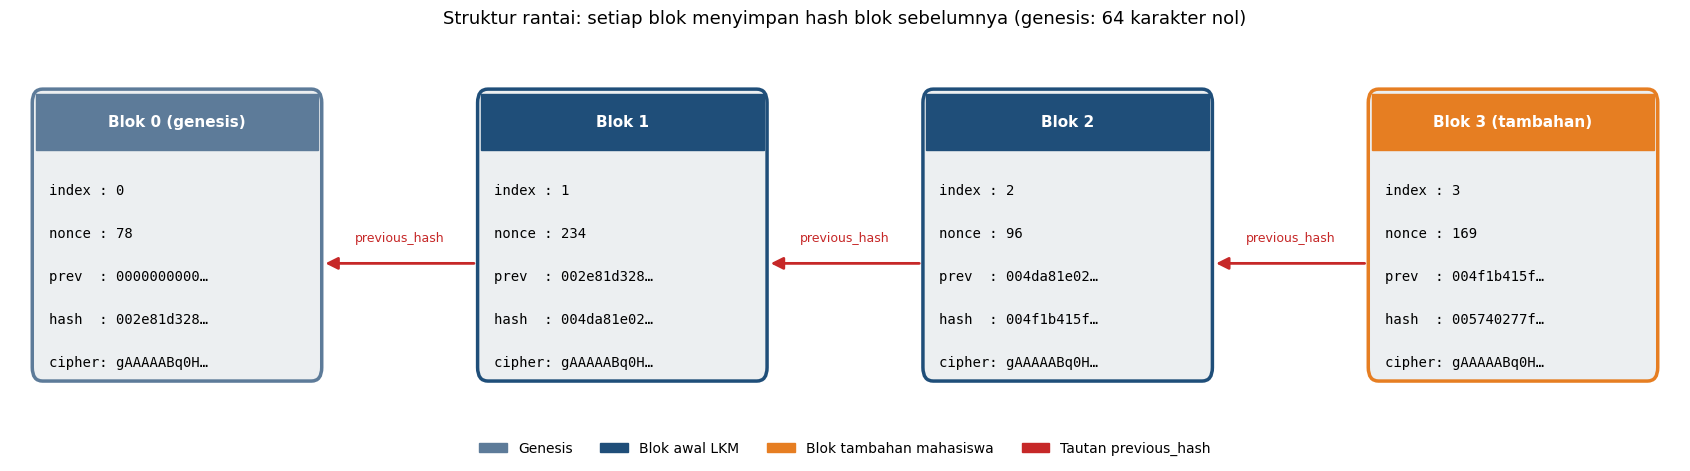

In [27]:
BIRU, ORANYE, ABU = "#1F4E79", "#E67E22", "#ECEFF1"
HIJAU, MERAH = "#2E7D32", "#C62828"

def gambar_rantai(rantai):
    lebar, tinggi, jarak = 3.3, 2.5, 1.9
    fig, ax = plt.subplots(figsize=(17, 4.8))
    for i, b in enumerate(rantai):
        x = i * (lebar + jarak)
        warna = ORANYE if i >= 3 else (BIRU if i > 0 else "#5D7B99")
        ax.add_patch(FancyBboxPatch((x, 0), lebar, tinggi, boxstyle="round,pad=0.04,rounding_size=0.12",
                                    facecolor=ABU, edgecolor=warna, linewidth=2.5))
        ax.add_patch(Rectangle((x, tinggi - 0.5), lebar, 0.5, facecolor=warna, edgecolor=warna))
        judul = "Blok 0 (genesis)" if i == 0 else (f"Blok {i} (tambahan)" if i >= 3 else f"Blok {i}")
        ax.text(x + lebar / 2, tinggi - 0.25, judul, ha="center", va="center", color="white", fontsize=11, fontweight="bold")
        baris = [f"index : {b['index']}", f"nonce : {b['nonce']}",
                 f"prev  : {b['previous_hash'][:10]}…", f"hash  : {b['hash'][:10]}…",
                 f"cipher: {b['ciphertext'][:10]}…"]
        for k, t in enumerate(baris):
            ax.text(x + 0.15, tinggi - 0.85 - k * 0.38, t, family="monospace", fontsize=10, va="center")
        if i > 0:
            x_prev_kanan = (i - 1) * (lebar + jarak) + lebar
            ax.add_patch(FancyArrowPatch((x - 0.05, 1.0), (x_prev_kanan + 0.05, 1.0),
                                         arrowstyle="-|>", mutation_scale=18, color=MERAH, linewidth=2))
            ax.text((x + x_prev_kanan) / 2, 1.2, "previous_hash", ha="center", fontsize=9, color=MERAH)
    ax.set_xlim(-0.3, len(rantai) * (lebar + jarak) - jarak + 0.3)
    ax.set_ylim(-0.4, tinggi + 0.5)
    ax.axis("off")
    ax.set_title("Struktur rantai: setiap blok menyimpan hash blok sebelumnya (genesis: 64 karakter nol)", fontsize=13, pad=10)
    ax.legend(handles=[Patch(color="#5D7B99", label="Genesis"), Patch(color=BIRU, label="Blok awal LKM"),
                       Patch(color=ORANYE, label="Blok tambahan mahasiswa"),
                       Patch(color=MERAH, label="Tautan previous_hash")],
              loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.12))
    plt.tight_layout(); plt.show()

gambar_rantai(chain)

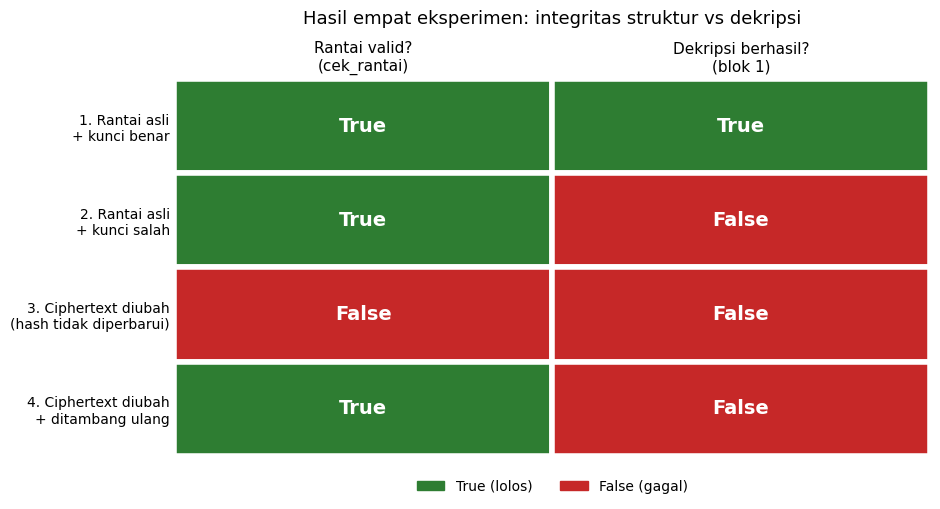

In [28]:
nama_pendek = ["1. Rantai asli\n+ kunci benar", "2. Rantai asli\n+ kunci salah",
               "3. Ciphertext diubah\n(hash tidak diperbarui)", "4. Ciphertext diubah\n+ ditambang ulang"]
n = len(hasil)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for i, h in enumerate(hasil):
    for j, nilai in enumerate([h["valid"], h["dekripsi_ok"]]):
        y = n - 1 - i
        ax.add_patch(Rectangle((j, y), 1, 1, facecolor=HIJAU if nilai else MERAH, edgecolor="white", linewidth=4))
        ax.text(j + 0.5, y + 0.5, str(nilai), ha="center", va="center", color="white", fontsize=14, fontweight="bold")
ax.set_xlim(0, 2); ax.set_ylim(0, n)
ax.set_xticks([0.5, 1.5]); ax.set_xticklabels(["Rantai valid?\n(cek_rantai)", "Dekripsi berhasil?\n(blok 1)"], fontsize=11)
ax.xaxis.tick_top()
ax.set_yticks([n - 1 - i + 0.5 for i in range(n)]); ax.set_yticklabels(nama_pendek, fontsize=10)
ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Hasil empat eksperimen: integritas struktur vs dekripsi", fontsize=13, pad=40)
ax.legend(handles=[Patch(color=HIJAU, label="True (lolos)"), Patch(color=MERAH, label="False (gagal)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.03), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

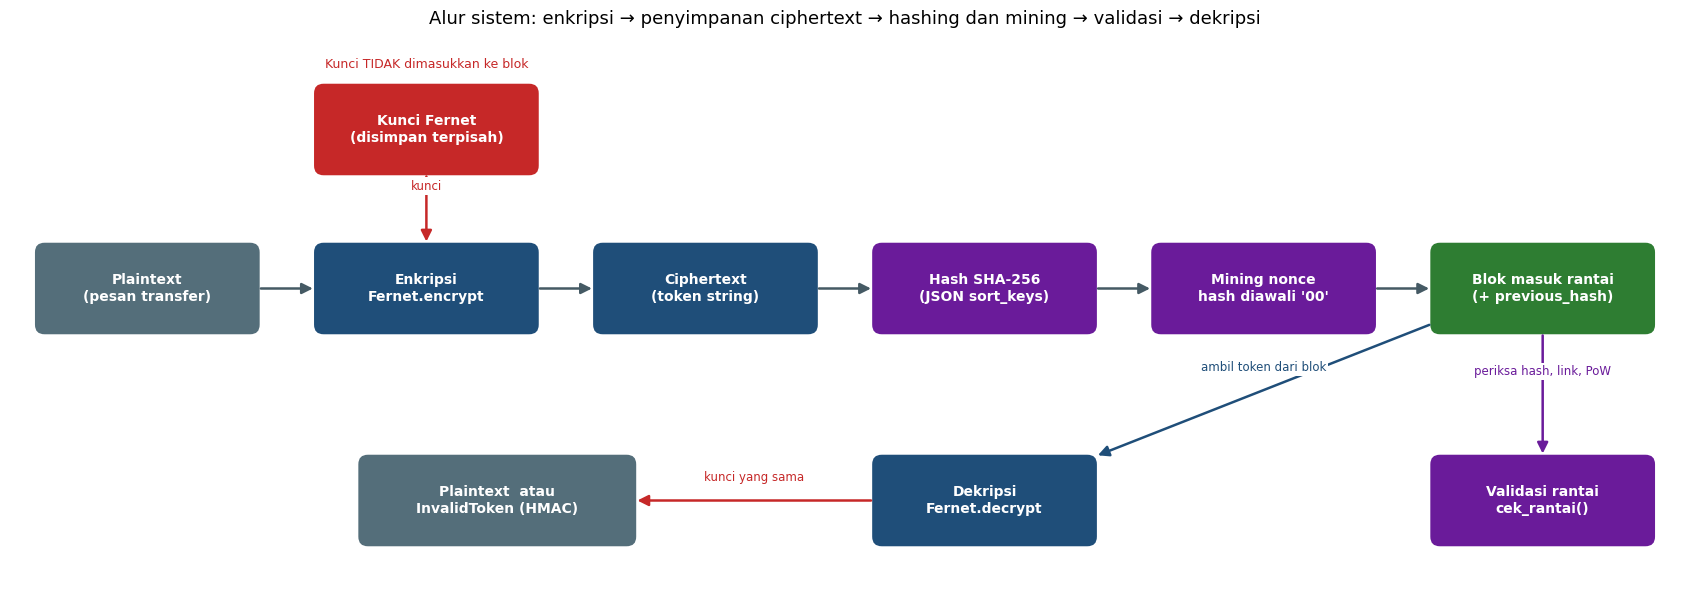

In [29]:
def kotak(ax, x, y, w, h, teks, warna):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12",
                                facecolor=warna, edgecolor="white", linewidth=1.5))
    ax.text(x + w / 2, y + h / 2, teks, ha="center", va="center", color="white", fontsize=10, fontweight="bold")

def panah(ax, a, b, label=None, warna="#455A64", gaya="-|>"):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle=gaya, mutation_scale=16, color=warna, linewidth=1.8))
    if label:
        ax.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2 + 0.22, label, ha="center", fontsize=8.5, color=warna, bbox=dict(facecolor="white", edgecolor="none", pad=1.5))

fig, ax = plt.subplots(figsize=(17, 6))
w, h, g = 2.5, 1.0, 0.65
xs = [i * (w + g) for i in range(6)]
atas = [("Plaintext\n(pesan transfer)", "#546E7A"), ("Enkripsi\nFernet.encrypt", BIRU), ("Ciphertext\n(token string)", BIRU),
        ("Hash SHA-256\n(JSON sort_keys)", "#6A1B9A"), ("Mining nonce\nhash diawali '00'", "#6A1B9A"),
        ("Blok masuk rantai\n(+ previous_hash)", HIJAU)]
for x, (t, c) in zip(xs, atas): kotak(ax, x, 3.0, w, h, t, c)
for i in range(5): panah(ax, (xs[i] + w, 3.5), (xs[i + 1], 3.5))
kotak(ax, xs[1], 4.8, w, h, "Kunci Fernet\n(disimpan terpisah)", MERAH)
panah(ax, (xs[1] + w / 2, 4.8), (xs[1] + w / 2, 4.0), "kunci", MERAH)
ax.text(xs[1] + w / 2, 6.0, "Kunci TIDAK dimasukkan ke blok", ha="center", fontsize=9, color=MERAH)

kotak(ax, xs[5], 0.6, w, h, "Validasi rantai\ncek_rantai()", "#6A1B9A")
panah(ax, (xs[5] + w / 2, 3.0), (xs[5] + w / 2, 1.6), "periksa hash, link, PoW", "#6A1B9A")
kotak(ax, xs[3], 0.6, w, h, "Dekripsi\nFernet.decrypt", BIRU)
kotak(ax, xs[1] + 0.5, 0.6, w + 0.6, h, "Plaintext  atau\nInvalidToken (HMAC)", "#546E7A")
panah(ax, (xs[5], 3.1), (xs[3] + w, 1.6), "ambil token dari blok", BIRU)
panah(ax, (xs[3], 1.1), (xs[1] + 0.5 + w + 0.6, 1.1), "kunci yang sama", MERAH)
ax.set_xlim(-0.3, xs[5] + w + 0.3); ax.set_ylim(0.2, 6.4); ax.axis("off")
ax.set_title("Alur sistem: enkripsi → penyimpanan ciphertext → hashing dan mining → validasi → dekripsi", fontsize=13)
plt.tight_layout(); plt.show()

## I. Analisis

Sel kode berikut mencetak bukti dari eksperimen dan demonstrasi kecil yang dipakai pada jawaban (a), (b), dan (c).

In [30]:
uji = "Andi kirim 10 kredit ke Bima"
sha = lambda s: hashlib.sha256(s.encode()).hexdigest()
print("(a) Panjang hash pesan pendek :", len(sha("a")), "karakter hex")
print("    Panjang hash pesan panjang:", len(sha(uji * 50)), "karakter hex")
t_a, t_b = f.encrypt(uji.encode()).decode(), f.encrypt(uji.encode()).decode()
print("    Dua token dari plaintext sama berbeda:", t_a != t_b, "(Fernet memakai IV acak)")
print("    Keduanya dapat didekripsi ke plaintext sama:",
      f.decrypt(t_a.encode()) == f.decrypt(t_b.encode()) == uji.encode())
print("    Hash plaintext  :", sha(uji)[:24] + "…")
print("    Hash ciphertext :", sha(t_a)[:24] + "…  (berbeda dan tidak mengungkap plaintext)")

print("\n(b) Eksperimen 3 -> valid:", hasil[2]["valid"], "| dekripsi:", hasil[2]["hasil_dekripsi"])
print("    Eksperimen 4 -> valid:", hasil[3]["valid"], "| dekripsi:", hasil[3]["hasil_dekripsi"])
print("    Eksperimen 4, status dekripsi tiap blok:", ["OK" if ok else "InvalidToken" for ok, _ in hasil[3]["semua_dekripsi"]])


kunci_demo = Fernet.generate_key()
blok_buruk = {"index": 0, "previous_hash": GENESIS_PREV,
              "ciphertext": Fernet(kunci_demo).encrypt(b"Contoh pesan rahasia").decode(),
              "kunci": kunci_demo.decode()}                       
blok_buruk["hash"] = hash_blok(blok_buruk)
print("\n(c) Hash blok buruk tetap konsisten:", blok_buruk["hash"] == hash_blok(blok_buruk))
pembaca = Fernet(blok_buruk["kunci"].encode())                   
print("    Pihak yang hanya memegang blok dapat membaca:", pembaca.decrypt(blok_buruk["ciphertext"].encode()).decode())

(a) Panjang hash pesan pendek : 64 karakter hex
    Panjang hash pesan panjang: 64 karakter hex
    Dua token dari plaintext sama berbeda: True (Fernet memakai IV acak)
    Keduanya dapat didekripsi ke plaintext sama: True
    Hash plaintext  : 5e56c81df5174b195a388579…
    Hash ciphertext : 3a7e2b0fc56e9515ee2ca65a…  (berbeda dan tidak mengungkap plaintext)

(b) Eksperimen 3 -> valid: False | dekripsi: InvalidToken
    Eksperimen 4 -> valid: True | dekripsi: InvalidToken
    Eksperimen 4, status dekripsi tiap blok: ['OK', 'InvalidToken', 'OK']

(c) Hash blok buruk tetap konsisten: True
    Pihak yang hanya memegang blok dapat membaca: Contoh pesan rahasia


### (a) Mengapa hash tidak dapat didekripsi menjadi pesan?

SHA-256 adalah **fungsi hash satu arah**. Input dengan panjang berapa pun dipadatkan menjadi output tetap 256 bit (64 karakter heksadesimal), seperti terlihat pada bukti: pesan pendek dan pesan panjang sama-sama menghasilkan 64 karakter. Karena banyak input berbeda dipetakan ke ruang output yang ukurannya tetap, sebagian besar informasi pesan hilang dan tidak ada operasi "dekripsi hash" yang mengembalikan pesan semula. Satu-satunya cara umum adalah menebak input lalu menghitung hash-nya.

Hashing dan enkripsi punya tujuan berbeda. Hash dipakai untuk **memeriksa apakah data berubah** (integritas). Enkripsi Fernet dirancang agar pesan dapat **dipulihkan oleh pemegang kunci** (kerahasiaan). Pada notebook ini yang di-hash adalah blok yang berisi *ciphertext*, bukan plaintext. Hash plaintext dan hash ciphertext berbeda, dan hash ciphertext tidak mengungkap pesan. Bukti lainnya: dua enkripsi atas plaintext yang sama menghasilkan token berbeda (IV acak), tetapi keduanya tetap terdekripsi ke pesan yang sama dengan kunci yang benar.

### (b) Mengapa rantai yang dibangun ulang dapat lolos pemeriksaan hash tetapi token tetap ditolak?

Pada Eksperimen 4, setelah ciphertext diubah, blok tersebut ditambang ulang: hash dihitung ulang, `nonce` dicari lagi sampai berawalan `00`, lalu `previous_hash` pada blok sesudahnya diperbarui dan blok itu ditambang ulang juga. Semua aturan struktural (hash cocok, tautan konsisten, PoW terpenuhi, indeks berurutan) terpenuhi, sehingga `cek_rantai()` mengembalikan `True`.

Namun pemeriksaan itu hanya menjawab pertanyaan "apakah rantai konsisten terhadap aturan hash?", bukan "apakah token dibuat oleh pemegang kunci?". SHA-256 dapat dihitung siapa saja karena tidak memerlukan rahasia. Fernet menyertakan HMAC-SHA256 pada token yang hanya dapat dihitung dengan kunci. Token yang diubah tidak memiliki HMAC yang cocok, sehingga `Fernet.decrypt()` melempar `InvalidToken`, seperti terlihat pada hasil Eksperimen 4. Blok yang ciphertext-nya tidak diubah tetap berhasil didekripsi, sehingga penolakan ini khusus pada token yang dimanipulasi.

**Asumsi:** penyerang tidak mengetahui kunci Fernet. Jika kunci bocor, pemegangnya dapat membuat token Fernet yang autentik, menambang ulang rantainya, dan hasilnya akan lolos kedua pemeriksaan. Simulasi lokal ini juga belum punya jaringan, konsensus, atau tanda tangan digital, sehingga validitas rantai tidak membuktikan identitas pengirim atau kebenaran transaksi.

### (c) Apa akibat menyimpan kunci dalam blok?

Siapa pun yang memegang blok (atau salinan rantai) dapat mengambil kunci dari blok itu lalu mendekripsi ciphertext terkait, seperti pada demonstrasi: pihak yang hanya memegang blok langsung dapat membaca pesan. Enkripsinya menjadi tidak berguna karena **kerahasiaan bergantung pada pengelolaan kunci**, bukan pada hashing blok. Ciphertext dan kunci harus disimpan terpisah.

Pada blockchain risikonya lebih besar karena data direplikasi ke banyak pihak dan umumnya tidak dapat dihapus, sehingga kunci yang telanjur masuk ke blok tersebar luas dan sulit ditarik kembali. Perlu dicatat bahwa hash blok tetap konsisten (lihat bukti): mekanisme hashing tidak otomatis rusak. Yang hilang adalah **kerahasiaan**, sedangkan integritas struktural dan kerahasiaan adalah dua properti yang berbeda. Selain itu, bila kunci bocor, pihak yang memilikinya juga dapat membuat token Fernet autentik baru, sehingga autentikasi token ikut melemah.

## J. Pengujian otomatis

Pengujian memakai `assert` dan dipisahkan menjadi pengujian **integritas** dan pengujian **dekripsi**. Semua pengujian memakai salinan rantai.

In [31]:
def uji(nama, kondisi):
    assert kondisi, f"GAGAL: {nama}"
    print("LULUS :", nama)

print("── Pengujian integritas ──")
uji("1. Rantai asli lolos validasi", cek_rantai(chain_asli))

t4 = copy.deepcopy(chain_asli)
t4[1]["ciphertext"] = ubah_ciphertext(t4[1]["ciphertext"])
uji("4. Perubahan ciphertext tanpa pembaruan hash terdeteksi",
    cek_rantai(t4) is False and cek_rantai(t4, detail=True)["hash_integritas"] is False)

t5 = copy.deepcopy(chain_asli)
t5[2]["previous_hash"] = "f" * 64
uji("5a. Perubahan previous_hash (tanpa tambang ulang) terdeteksi", cek_rantai(t5) is False)
tambang(t5[2])   
d5 = cek_rantai(t5, detail=True)
uji("5b. Perubahan previous_hash yang ditambang ulang tetap terdeteksi lewat tautan",
    d5["hash_integritas"] and d5["proof_of_work"] and d5["previous_hash"] is False and cek_rantai(t5) is False)

t6 = copy.deepcopy(chain_asli)
n = 0
while True:      
    t6[2]["nonce"] = n
    t6[2]["hash"] = hash_blok(t6[2])
    if not t6[2]["hash"].startswith(PREFIX_POW):
        break
    n += 1
d6 = cek_rantai(t6, detail=True)
uji("6. Blok dengan PoW tidak valid ditolak",
    d6["hash_integritas"] and d6["proof_of_work"] is False and cek_rantai(t6) is False)

t7 = copy.deepcopy(chain_asli)
t7[1]["ciphertext"] = ubah_ciphertext(t7[1]["ciphertext"])
tambang_ulang_dari(t7, 1)
uji("7. Rantai yang ditambang ulang dengan aturan benar lolos validasi", cek_rantai(t7))

t9 = copy.deepcopy(chain_asli)
tambah_blok("Uji blok baru", rantai=t9)
uji("9. Penambahan blok baru mempertahankan validitas rantai",
    cek_rantai(t9) and len(t9) == 4 and t9[3]["previous_hash"] == t9[2]["hash"])

print("\n── Pengujian dekripsi ──")
ok, teks = dekripsi_blok(chain_asli[1], f)
uji("2. Kunci benar dapat mendekripsi pesan", ok and teks == PESAN_AWAL[1])
ok, _ = dekripsi_blok(chain_asli[1], Fernet(Fernet.generate_key()))
uji("3. Kunci salah tidak dapat mendekripsi token", ok is False)
ok, _ = dekripsi_blok(t7[1], f)
uji("8. Token hasil manipulasi ditolak Fernet meski rantai lolos validasi", ok is False and cek_rantai(t7))
ok, teks = dekripsi_blok(t7[2], f)
uji("8b. Token yang tidak dimanipulasi pada rantai yang sama tetap terbaca", ok and teks == PESAN_AWAL[2])

print("\nSemua pengujian lulus.")

── Pengujian integritas ──
LULUS : 1. Rantai asli lolos validasi
LULUS : 4. Perubahan ciphertext tanpa pembaruan hash terdeteksi
LULUS : 5a. Perubahan previous_hash (tanpa tambang ulang) terdeteksi
LULUS : 5b. Perubahan previous_hash yang ditambang ulang tetap terdeteksi lewat tautan
LULUS : 6. Blok dengan PoW tidak valid ditolak
LULUS : 7. Rantai yang ditambang ulang dengan aturan benar lolos validasi
LULUS : 9. Penambahan blok baru mempertahankan validitas rantai

── Pengujian dekripsi ──
LULUS : 2. Kunci benar dapat mendekripsi pesan
LULUS : 3. Kunci salah tidak dapat mendekripsi token
LULUS : 8. Token hasil manipulasi ditolak Fernet meski rantai lolos validasi
LULUS : 8b. Token yang tidak dimanipulasi pada rantai yang sama tetap terbaca

Semua pengujian lulus.


## K. Kesimpulan

1. Tiga blok berantai berhasil dibangun (ditambah satu blok pesan buatan mahasiswa). Pesan dienkripsi dengan Fernet, disimpan sebagai ciphertext, dan dapat didekripsi hanya dengan kunci yang sesuai; kunci tidak disimpan di dalam blok.
2. **Hash dan rantai** memeriksa integritas struktur terhadap aturan yang ditetapkan (hash cocok, `previous_hash` konsisten, PoW, indeks). Perubahan ciphertext tanpa menghitung ulang hash terdeteksi (Eksperimen 3).
3. **Fernet** memberi kerahasiaan dan autentikasi token (HMAC). Kunci yang salah atau token yang diubah menghasilkan `InvalidToken` (Eksperimen 2, 3, dan 4).
4. **PoW dalam simulasi ini dapat dihitung ulang** oleh siapa saja. Eksperimen 4 menunjukkan rantai yang ditambang ulang lolos `cek_rantai()`, tetapi token yang diubah tetap ditolak Fernet selama kunci tidak bocor. Lolosnya validasi struktur tidak membuktikan bahwa data atau transaksi benar.
5. Kunci harus dikelola terpisah dari ciphertext. Kerahasiaan bergantung pada pengelolaan kunci, bukan pada hashing blok.
6. Simulasi ini bukan blockchain produksi atau sistem pembayaran: belum ada jaringan terdistribusi, konsensus, maupun tanda tangan digital, dan saldo tidak diproses.

## L. Referensi

- Python Cryptographic Authority. *Fernet (symmetric encryption)*, `cryptography` documentation. https://cryptography.io/en/latest/fernet/
- Python Software Foundation. *hashlib: Secure hashes and message digests*. https://docs.python.org/3/library/hashlib.html
- Python Software Foundation. *json: JSON encoder and decoder*. https://docs.python.org/3/library/json.html